# Temporal activity and community evolution

This notebook reads a **real completed** chronological Reddit experiment. It
does not fit models, select on test outcomes, invent annotations, or turn an
operational label into social ground truth. Run all five `temporal-study`
stages first. Use the project virtual environment with the graph, research and
notebook extras installed. Historical post-2015 outcome exposure is uncertified.

Five baselines are Majority, Persistence, flat dynamic LR, hierarchical static
HGB and hierarchical dynamic HGB. They accompany the original proposed
hierarchical dynamic LR and one matched no-dynamics ablation. Four tuned
families in the compact forward protocol use 192 configuration-fold evaluations
(two-head models fit up to two estimators each). The completed archived study
used a broader 480 configuration-fold selection design; its saved results are
not presented as a new compact-protocol rerun. HGB dynamic was an alternative architecture in the original
run; its reference role here is retrospective.
This is a post-evaluation presentation reduction, not a new independent run.
The reader verifies all original frozen predictions before projecting to seven
methods, retains the original primary/champion, and requires the original
champion interval to remain unchanged. The secondary strongest-reference
interval is reported separately.

## Submission scope and reading guide

Follow one task: forecast the next-month **six structural events** of an
existing detected user community. Read the dataset/graph/label audit, the five
named baselines, retained hierarchical dynamic LR, matched no-dynamics ablation,
external cohort and longitudinal observation limits in order.

The retained primary scores 0.4117 on the original and 0.3690 on the external
cohort. Its five named controls are weaker in point scores, but strongest paired
intervals include zero and the external no-dynamics ablation scores 0.3777.
These are preliminary results on operational labels, not stable superiority.
Rejected candidate model code and the separate continuous-target study are
archived locally and are not part of this notebook's submission flow.


In [1]:
# Find the project from either its root or notebooks/core. Use the installed
# package; never patch sys.path or select an unrelated global interpreter.
from pathlib import Path
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
run = project / "artifacts/temporal/activity-study-001"
from reddit_sna.reporting.temporal_study import read_compact_study, study_figures, study_diagnostics
data = read_compact_study(run)
display(Markdown("Prediction inventories and independently recomputed metrics verified."))

Prediction inventories and independently recomputed metrics verified.

## Problem, graph and target

The input is a detected user community at the end of month *t*. The output is
its next-month observed structural event. Reply edges connect comment author
to parent author; the undirected Leiden graph sums both directions. Subreddit
is context, not a labeled community. GED-adapted labels are tracker-derived:
stable means equal size on a one-to-one link; dissolve is loss of meaningful
observed inclusion, not proof of social disappearance. Final snapshots are
censored. Unresolved transitions remain in coverage reporting.

In [2]:
# Describe the measured population and preserve every support/exclusion count.
display(Markdown("### Measurement audit"))
display(data["label_audit"])
display(Markdown("### Exposure and remaining human review"))
display(data["exposure"])
display(Markdown("Human annotation and novelty verification remain pending."))

### Measurement audit

{'status': 'automated_rule_consistency_verified',
 'support': {'split': 166,
  'dissolve': 6867,
  'unresolved': 4072,
  'grow': 87,
  'merge': 229,
  'shrink': 125,
  'stable': 16},
 'reasons': {'multiple_successors': 166,
  'below_dissolve_threshold': 6867,
  'weak_overlap_unresolved': 4072,
  'one_to_one_size_comparison': 228,
  'multiple_predecessors': 229,
  'final_snapshot_censored': 183},
 'size_strata': {'split:size_ge10': 166,
  'dissolve:size_ge10': 277,
  'unresolved:size_le2': 2770,
  'dissolve:size_le2': 4576,
  'dissolve:size_3to9': 2014,
  'grow:size_le2': 66,
  'merge:size_le2': 153,
  'unresolved:size_3to9': 1018,
  'unresolved:size_ge10': 284,
  'merge:size_3to9': 76,
  'shrink:size_ge10': 114,
  'grow:size_3to9': 21,
  'stable:size_3to9': 1,
  'shrink:size_3to9': 11,
  'stable:size_le2': 15},
 'human_review': 'pending',
 'target': 'GED-adapted observed structural events, not social ground truth',
 'stable': 'equal size on accepted one-to-one link; membership may diff

### Exposure and remaining human review

{'known': '2015 forecasts and full-period aggregate inventory inspected',
 'previous_post2015_forecast_exposure': 'not independently established',
 'unseen': False}

Human annotation and novelty verification remain pending.

In [3]:
# Primary method and baseline champion were chosen before final evaluation.
# Keep the strongest realized baseline visible even if it defeats proposed.
result = data["evaluation"]
table = "| Model | Fixed-six-class Macro-F1 |\n|---|---:|\n"
table += "\n".join(f"| {name} | {value:.4f} |" for name, value in
                   sorted(result["mean_macro_f1"].items(), key=lambda item: -item[1]))
display(Markdown(table))
display(study_diagnostics(data))
display({key: result[key] for key in ("proposed", "validation_selected_champion",
    "strongest_realized_baseline", "delta_vs_strongest", "intervals", "superiority")})

| Model | Fixed-six-class Macro-F1 |
|---|---:|
| hier_lr_dynamic | 0.4117 |
| hier_hgb_dynamic | 0.3880 |
| hier_hgb_static | 0.3728 |
| A_no_dynamics_matched | 0.3643 |
| flat_lr_dynamic | 0.3616 |
| B1_majority | 0.1597 |
| B1_persistence | 0.1562 |

{'strongest_reference': 'hier_hgb_dynamic',
 'secondary_interval': {'low': -0.08279976887233198,
  'high': 0.0983841175983789,
  'draws': 2000,
  'block_length': 3,
  'scope': 'paired exploratory monthly blocks; pseudo-label validity separate'},
 'secondary_superiority': 'not_demonstrated',
 'per_class': {'hier_lr_dynamic': [{'label': 'stable',
    'support': 4,
    'f1': 0.0},
   {'label': 'grow', 'support': 19, 'f1': 0.09677419354838708},
   {'label': 'shrink', 'support': 25, 'f1': 0.4444444444444444},
   {'label': 'merge', 'support': 15, 'f1': 0.23076923076923075},
   {'label': 'split', 'support': 39, 'f1': 0.7397260273972602},
   {'label': 'dissolve', 'support': 1167, 'f1': 0.9587136027813994}],
  'hier_hgb_dynamic': [{'label': 'stable', 'support': 4, 'f1': 0.0},
   {'label': 'grow', 'support': 19, 'f1': 0.1276595744680851},
   {'label': 'shrink', 'support': 25, 'f1': 0.4666666666666666},
   {'label': 'merge', 'support': 15, 'f1': 0.11320754716981134},
   {'label': 'split', 'suppor

{'proposed': 'hier_lr_dynamic',
 'validation_selected_champion': 'hier_hgb_static',
 'strongest_realized_baseline': 'hier_hgb_dynamic',
 'delta_vs_strongest': 0.023692458771724823,
 'intervals': {'hier_hgb_static': {'low': 0.005616971178524999,
   'high': 0.07444987582713058,
   'draws': 2000,
   'block_length': 3,
   'scope': 'paired exploratory monthly blocks; pseudo-label validity separate'}},
 'superiority': 'supported_on_this_operational_target'}

### Comparison

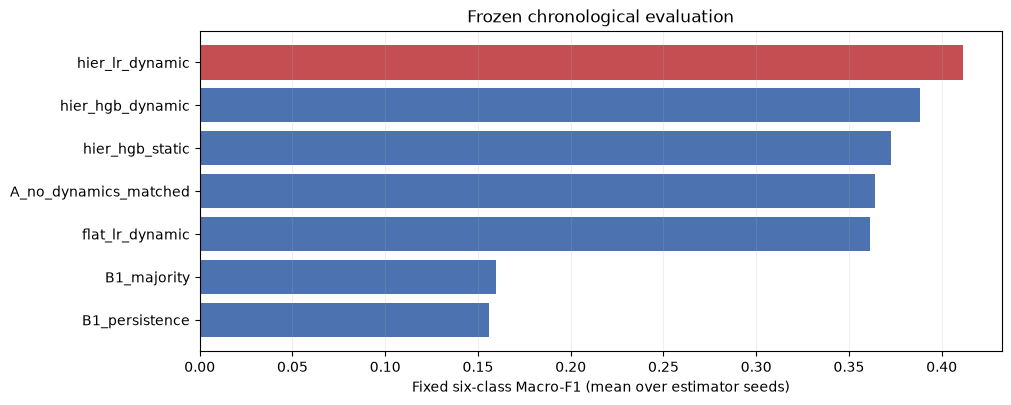

### Monthly

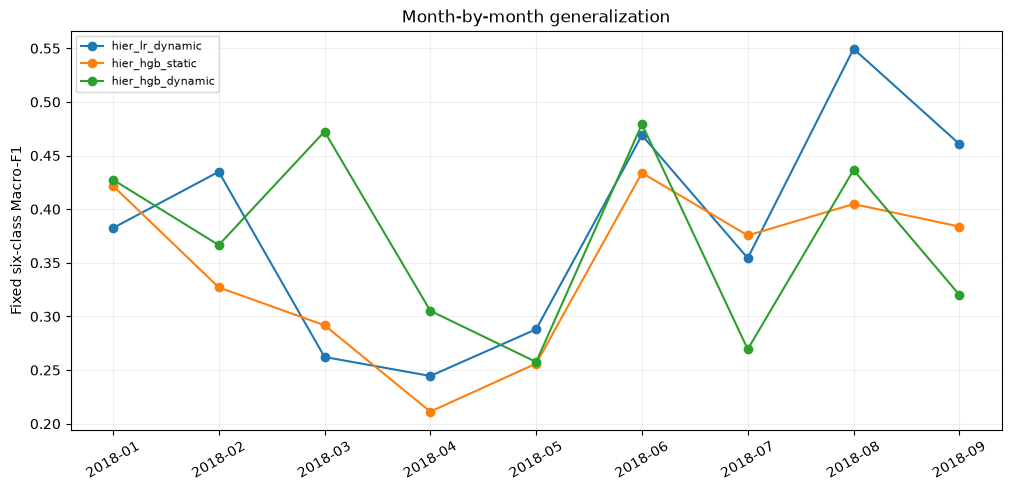

### Support

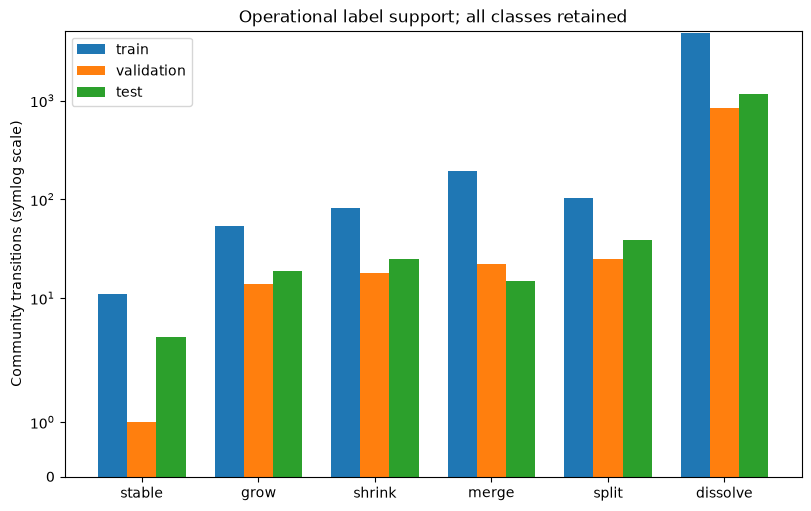

### Confusion

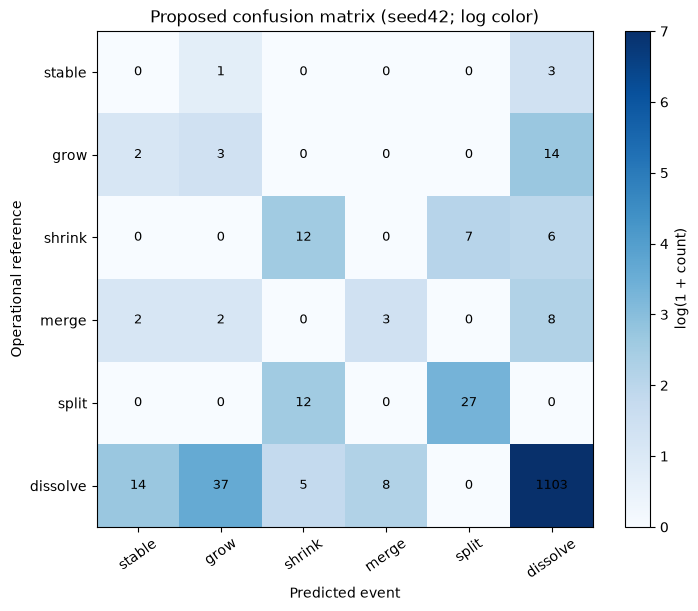

### Flow

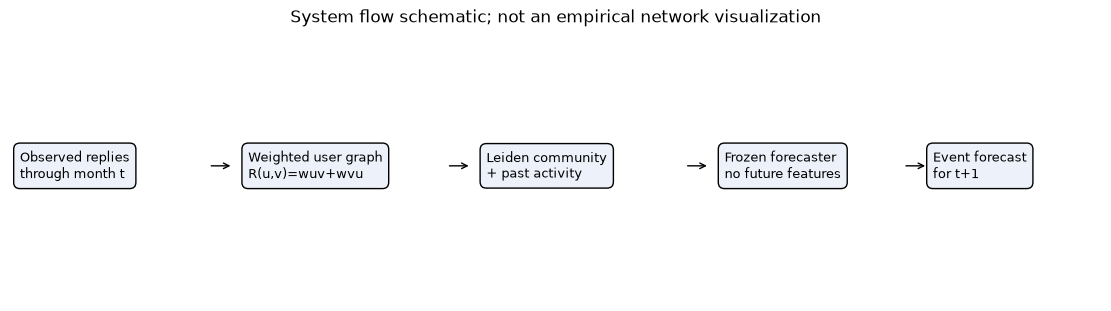

### Graph Scale

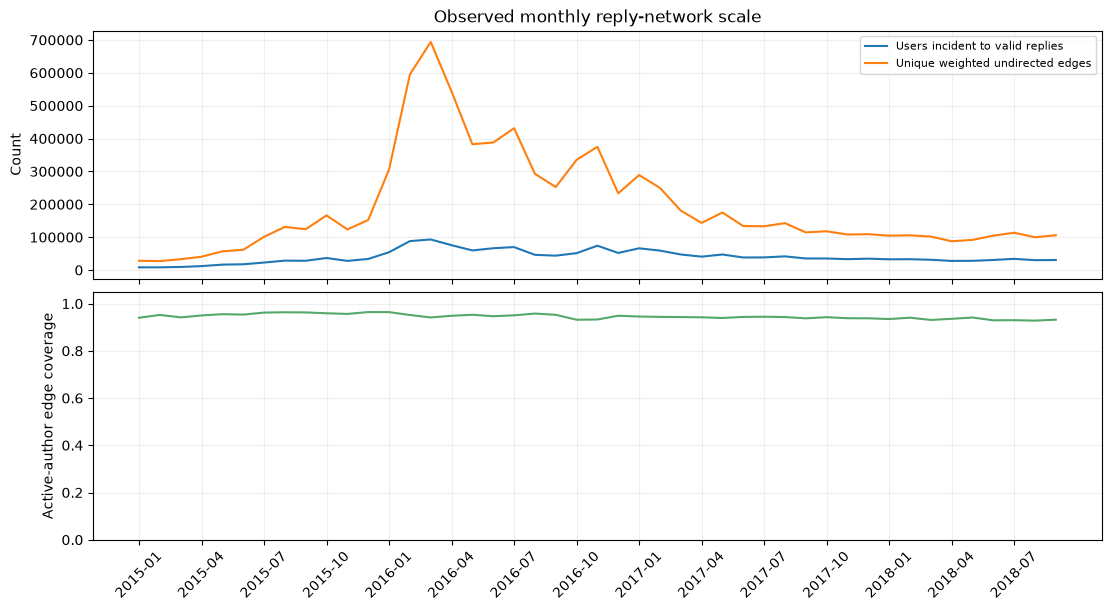

### Community Graph

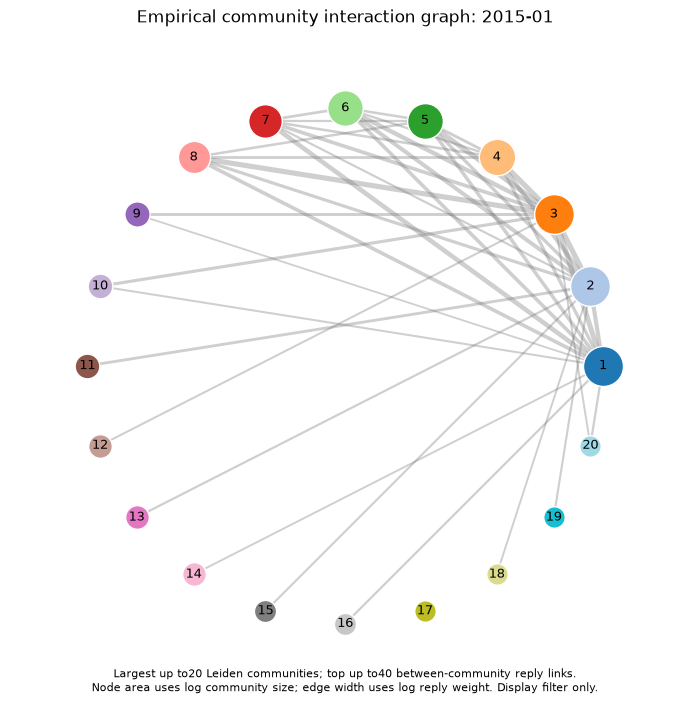

In [4]:
# Show real comparison, monthly generalization, class support and confusion.
# The flow chart is explicitly a schematic, not measured network evidence.
figures = study_figures(data)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)

## Interpretation

Compare the primary proposed method with both the validation-selected champion
and every stronger realized fair baseline. The matched no-dynamics ablation tests dynamic features at fixed settings.
The independently tuned flat LR uses the same inputs to assess hierarchy. Fixed-six-class F1
retains absent classes; read class support, size strata, unresolved coverage and
per-month performance alongside its aggregate. Block intervals use months, not
estimator seeds, as the resampling unit. A failed superiority criterion remains
a negative finding and does not authorize another search on these test labels.

Sources: [ConvoKit corpus](https://convokit.cornell.edu/documentation/subreddit.html),
[GED](https://doi.org/10.1007/s13278-012-0058-8),
[Leiden](https://doi.org/10.1038/s41598-019-41695-z),
[temporal evaluation](https://scikit-learn.org/stable/modules/cross_validation.html).

## Locked external replication

This separate three-corpus replication reuses fixed original settings, with no
new search. Its 2018 targets are prepared after the new development/model/source
freeze. Scores belong to different cohorts and are not pooled. Accounts may
overlap; prior group exposure is uncertified. Two blinded automated structural
assessments are supplementary evidence. Human annotation remains pending.
Complete the four `confirm-study` stages and both `study-agreement` summaries
before running this section. Private raw and case-level files stay local.

### Fixed external comparison

{'mean_macro_f1': {'B1_majority': 0.1554726368159204,
  'B1_persistence': 0.15499351491569388,
  'flat_lr_dynamic': 0.34513400156394397,
  'hier_hgb_static': 0.28995834806868637,
  'hier_hgb_dynamic': 0.3500203649397198,
  'hier_lr_dynamic': 0.3690119360222453,
  'A_no_dynamics_matched': 0.37769432709191747},
 'delta_vs_champion': 0.018991571082525527,
 'delta_vs_strongest': 0.018991571082525527,
 'intervals': {'hier_hgb_dynamic': {'low': -0.26310911310911317,
   'high': 0.21007963698540003,
   'draws': 2000,
   'block_length': 3,
   'scope': 'paired exploratory monthly blocks; pseudo-label validity separate'}},
 'superiority': 'not_demonstrated'}

### Supplementary structural agreement

{'development': {'cases': 35,
  'reviewer_type': 'automated',
  'raw_agreement': 0.9714285714285714,
  'cohen_kappa': 0.9591598599766629,
  'human_review': 'pending'},
 'final': {'cases': 34,
  'reviewer_type': 'automated',
  'raw_agreement': 0.9411764705882353,
  'cohen_kappa': 0.9177750906892382,
  'human_review': 'pending'}}

### Complete coverage and development-only target sensitivity

{'periods': {'train': {'labels': Counter({'unresolved': 638,
            'dissolve': 607,
            'merge': 42,
            'shrink': 34,
            'grow': 19,
            'split': 16,
            'stable': 2}),
   'reasons': Counter({'weak_overlap_unresolved': 636,
            'below_dissolve_threshold': 607,
            'one_to_one_size_comparison': 55,
            'multiple_predecessors': 42,
            'multiple_successors': 16,
            'many_to_many_unresolved': 2}),
   'sizes': Counter({'dissolve:le2': 380,
            'unresolved:le2': 332,
            'dissolve:3to9': 167,
            'unresolved:3to9': 158,
            'unresolved:ge10': 148,
            'dissolve:ge10': 60,
            'shrink:ge10': 32,
            'merge:le2': 22,
            'merge:3to9': 19,
            'split:ge10': 16,
            'grow:le2': 11,
            'grow:3to9': 8,
            'shrink:3to9': 2,
            'stable:le2': 2,
            'merge:ge10': 1}),
   'censored': 0,
   'observed_

### External comparison

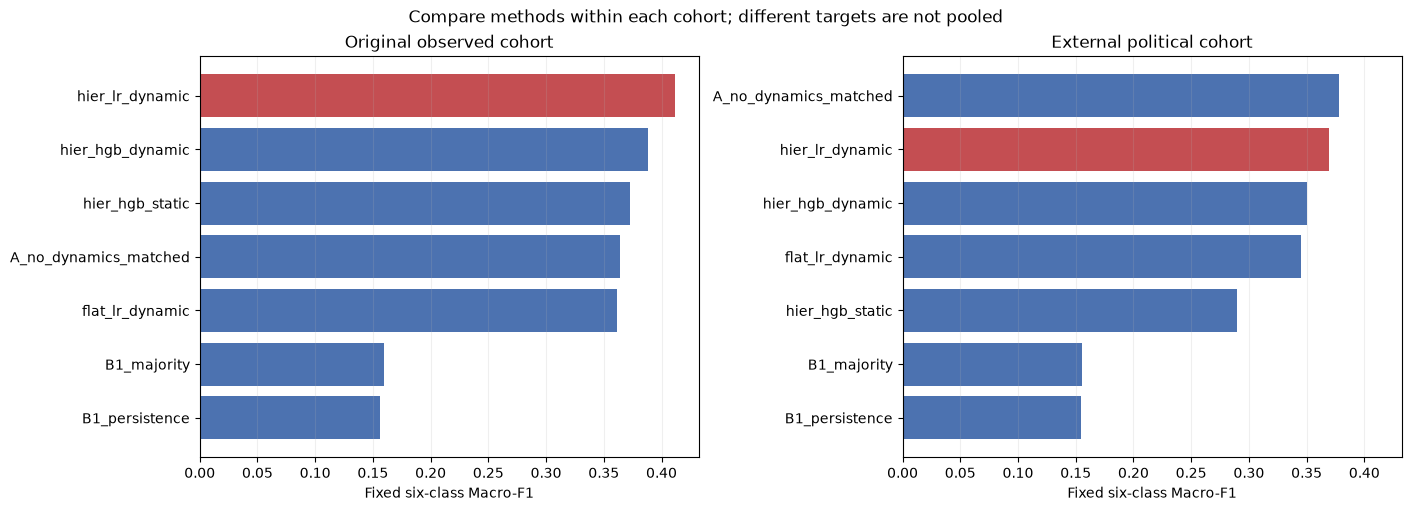

### External monthly

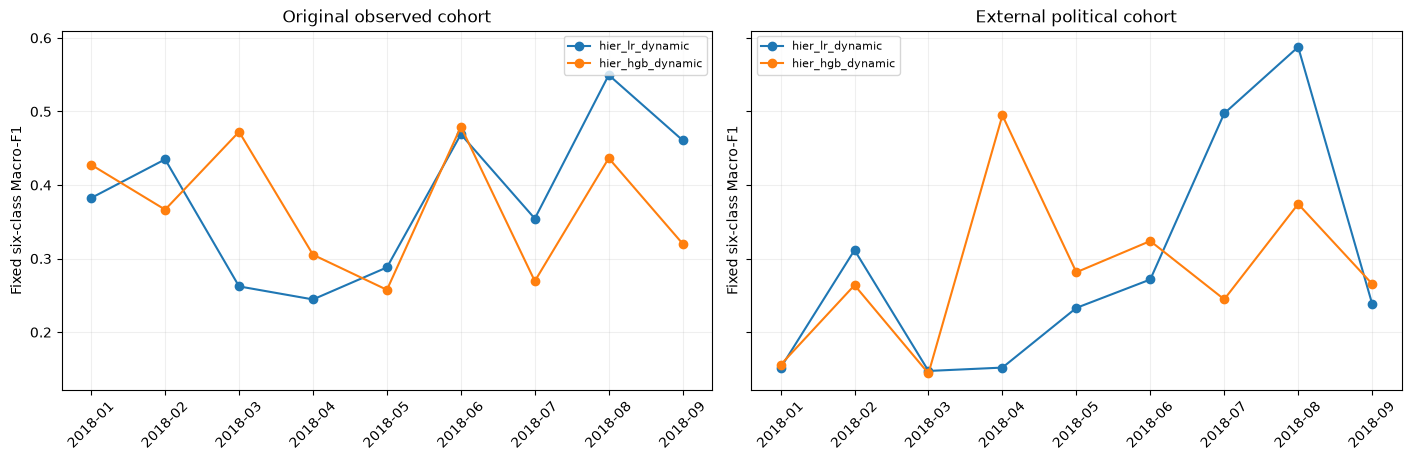

### External support

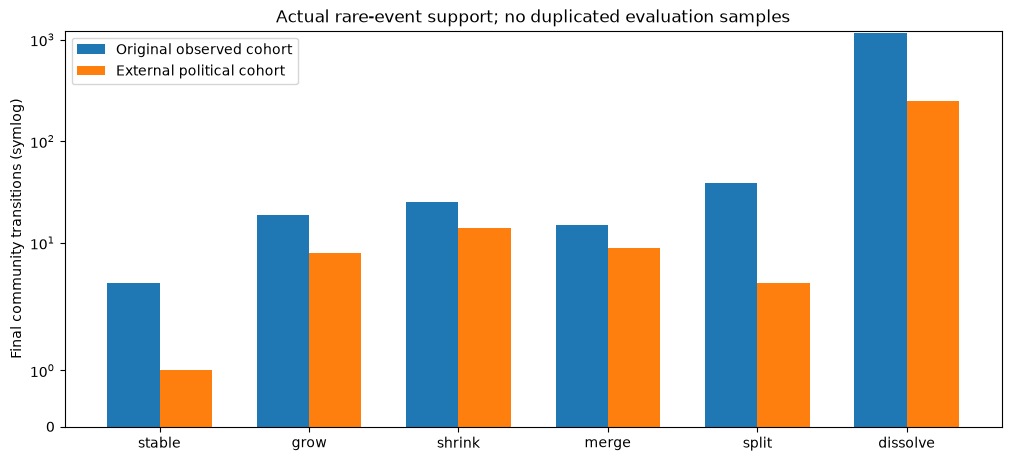

In [5]:
# Verify actual predictions and source-bound review summaries before display.
from reddit_sna.reporting.confirmation import read_confirmation, confirmation_figures
confirmation = read_confirmation(
    run, project / "artifacts/confirmation/political-cohort-001",
    project / "artifacts/validation/review-panel-001")
external = confirmation["confirmation"]["evaluation"]
display(Markdown("### Fixed external comparison"))
display({key: external[key] for key in ("mean_macro_f1", "delta_vs_champion",
    "delta_vs_strongest", "intervals", "superiority")})
# Report aggregation only: never display private case identities or judgments.
display(Markdown("### Supplementary structural agreement"))
display({period: {key: values[key] for key in
    ("cases", "reviewer_type", "raw_agreement", "cohen_kappa", "human_review")}
    for period, values in confirmation["reviews"].items()})
display(Markdown("### Complete coverage and development-only target sensitivity"))
display(confirmation["coverage"])
for name, figure in confirmation_figures(confirmation).items():
    display(Markdown(f"### External {name}"))
    display(figure)
    plt.close(figure)

## Limits of the confirmation

Interpret method differences within each cohort, with fixed six-class Macro-F1
and paired three-month-block uncertainty. Do not treat an interval containing
zero as proof of superiority. Stable-class scarcity and unresolved cases remain
visible even if the external point estimate improves. Automated agreement is not
independent human validation or social ground truth. No label, threshold or model
is changed using these final outcomes. See the integrated report for the actual
findings and the remaining research work.

## Development-only longitudinal observability

One-month low inclusion does not prove social death. Compare the fixed source
membership against partitions at t+1, t+2 and t+3. These separate original/external
audits use only development observations before January 2018. Censored and unknown
coverage windows stay in the denominators. Authorship and reply visibility differ.
No audit attribute enters a forecast feature and no label/model is replaced.
Run `audit-continuity` separately for each cohort before executing this section.
The archived matched-flat comparison below is explicitly retrospective and uses
saved held-out predictions separately from the development-only audit.

### Original: follow-up denominators

{'dimension': 'all',
 'value': 'all',
 'sources': 9946,
 'counts': {'accepted_next_month': 199,
  'coverage_unknown': 5374,
  'later_match_candidate': 81,
  'no_accepted_match_in_observed_window': 3642,
  'right_censored': 650}}

[{'horizon': 1,
  'sources': 9946,
  'observed': 4356,
  'right_censored': 216,
  'coverage_unknown': 5374},
 {'horizon': 2,
  'sources': 9946,
  'observed': 4134,
  'right_censored': 438,
  'coverage_unknown': 5374},
 {'horizon': 3,
  'sources': 9946,
  'observed': 3922,
  'right_censored': 650,
  'coverage_unknown': 5374}]

### External: follow-up denominators

{'dimension': 'all',
 'value': 'all',
 'sources': 1796,
 'counts': {'accepted_next_month': 134,
  'later_match_candidate': 75,
  'no_accepted_match_in_observed_window': 1443,
  'right_censored': 144}}

[{'horizon': 1,
  'sources': 1796,
  'observed': 1759,
  'right_censored': 37,
  'coverage_unknown': 0},
 {'horizon': 2,
  'sources': 1796,
  'observed': 1722,
  'right_censored': 74,
  'coverage_unknown': 0},
 {'horizon': 3,
  'sources': 1796,
  'observed': 1652,
  'right_censored': 144,
  'coverage_unknown': 0}]

### Retrospective matched architecture diagnostic

{'status': 'retrospective_auxiliary',
 'macro_f1': {'hier_lr_dynamic': 0.41173791649012026,
  'A_flat_matched': 0.33214719129092957},
 'matched_fields': ['size',
  'internal_edges',
  'internal_weight',
  'boundary_weight',
  'density',
  'community_age',
  'history_missing',
  'predecessor_count',
  'past_growth',
  'past_retention',
  'inflow_fraction',
  'outflow_fraction',
  'lag_size',
  'lag_density',
  'lag_internal_weight',
  'lag_missing',
  'subreddit_entropy',
  'thread_activity',
  'active_member_fraction',
  'co_thread_external_exposure',
  'records_per_member_log',
  'active_day_fraction',
  'recent_record_fraction',
  'top_member_fraction',
  'internal_reply_fraction',
  'weighted_reciprocity',
  'activity_missing',
  'reply_missing',
  'returning_member_fraction',
  'past_active_month_fraction',
  'record_log_growth',
  'reply_log_growth',
  'repeated_dyad_fraction',
  'context_drift_js',
  'past_window_fraction',
  'context_history_missing',
  'previous_reply_missing']

{'status': 'unavailable',
 'reason': 'No archived matched-flat control in this cohort'}

### Followup

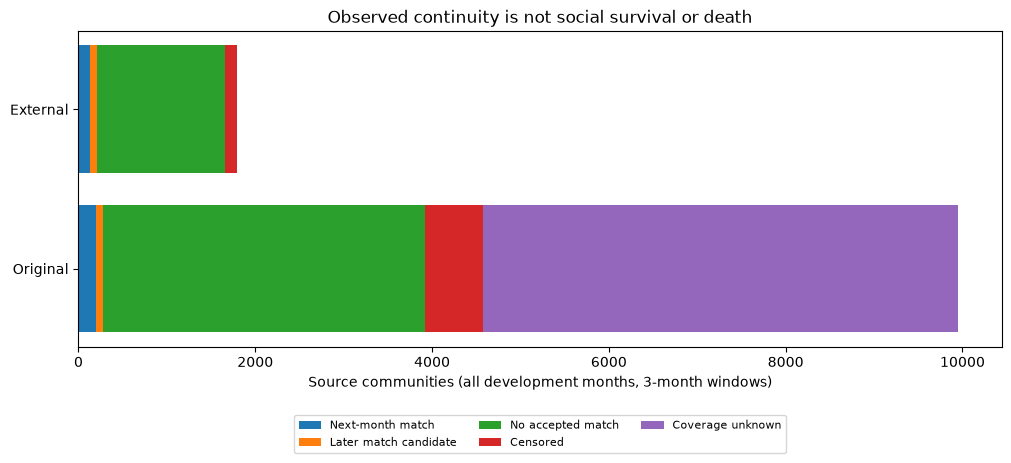

### Observation

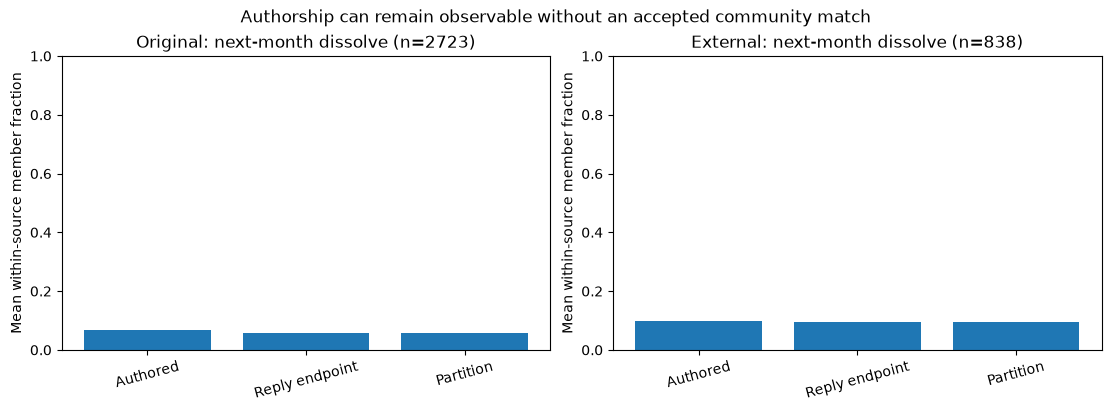

### Repeatability

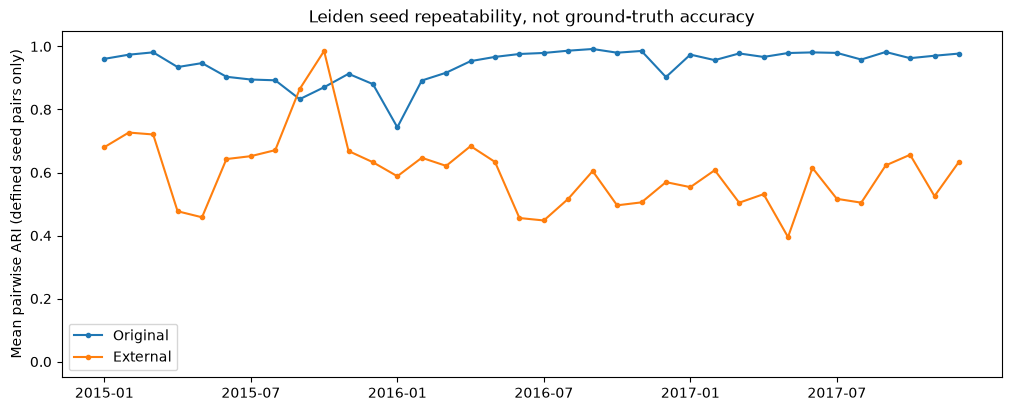

In [6]:
# Read sealed aggregate evidence. Do not display private case/user identifiers.
from reddit_sna.reporting.longitudinal import read_audit, matched_architecture, audit_figures
audits = {name: read_audit(project / f"artifacts/validation/continuity-{suffix}-002/audit")
          for name, suffix in (("Original", "original"), ("External", "external"))}
for name, data in audits.items():
    display(Markdown(f"### {name}: follow-up denominators"))
    display(next(s for s in data["summary"]["strata"] if s["dimension"] == "all"))
    display(data["summary"]["horizon_support"])
# This diagnostic verifies identical fields/settings/keys; it does not fit/select.
display(Markdown("### Retrospective matched architecture diagnostic"))
display(matched_architecture(run))
display(matched_architecture(project / "artifacts/confirmation/political-cohort-001"))
for name, figure in audit_figures(audits).items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)

## Controlled hierarchy and dynamics evidence

This finite supplementary study changes one component at a time while holding
the primary LR settings fixed. A2 is a matched architecture control and the
five D deletions test distinct behavioral or observation groups. All results
are retrospective. They do not select a new primary on exposed final data.
The reader below verifies sealed predictions and recomputes the tables.


## 9. Controlled component evidence

The finite comparison inventory was declared before this supplementary run.
Every configuration uses the primary LR settings (C=1, balanced class weighting,
standard scaling and max_iter=3000), seeds 42/43/44 and the same sample keys.
A2 changes only flat versus two-head organization. A1 removes all nine D fields.
The five grouped deletions remove member-return, activity-growth, repeated-dyad,
context-drift or observation/coverage fields separately. Behavioral deletions
retain the observation flags. The controls are ablations, not extra baselines.

Six expanding development origins cover July to December 2017. Final refits
use data through December 2017 and predict January to September 2018 without
refitting on those outcomes. Both periods were already exposed before this
supplementary study. No new primary is selected from these results.

| Configuration | Original development | Original final | External development | External final |
|---|---:|---:|---:|---:|
| full | 0.4350 | 0.4117 | 0.2712 | 0.3690 |
| A1_no_D | 0.3967 | 0.3643 | 0.2840 | 0.3777 |
| A2_flat_matched | 0.3338 | 0.3321 | 0.2809 | 0.3142 |
| without_member_return | 0.4239 | 0.3673 | 0.2533 | 0.3680 |
| without_activity_growth | 0.4394 | 0.4134 | 0.3124 | 0.3894 |
| without_repeated_dyads | 0.4150 | 0.3980 | 0.3082 | 0.3851 |
| without_context_drift | 0.4271 | 0.4255 | 0.2740 | 0.3657 |
| without_observation_flags | 0.4428 | 0.4126 | 0.2935 | 0.3551 |

Scores are means over three algorithm seeds. Historical full-primary and A1
final predictions were reproduced exactly before interpreting component effects.
The following differences are full minus the named control. Positive values
favor the full configuration. Intervals use the same paired three-month block
resamples for every comparison, 2000 draws and bootstrap seed 2026. These are
descriptive, unadjusted intervals across a finite set of comparisons, not a
new independent confirmation or a causal attribution to social mechanisms.
The six-month development window is too short for the declared minimum of
three block lengths, so its interval is explicitly unavailable.

| Cohort | Control | Full minus control | Descriptive 95% interval | Months full higher |
|---|---|---:|---|---:|
| original | A1_no_D | +0.0474 | [-0.0124, +0.0955] | 6/9 |
| original | A2_flat_matched | +0.0796 | [+0.0291, +0.1106] | 7/9 |
| original | without_member_return | +0.0445 | [-0.0160, +0.0916] | 5/9 |
| original | without_activity_growth | -0.0017 | [-0.0333, +0.0016] | 2/9 |
| original | without_repeated_dyads | +0.0137 | [-0.0116, +0.0272] | 3/9 |
| original | without_context_drift | -0.0138 | [-0.0375, +0.0012] | 1/9 |
| original | without_observation_flags | -0.0009 | [-0.0072, +0.0015] | 0/9 |
| external | A1_no_D | -0.0087 | [-0.0180, +0.0287] | 2/9 |
| external | A2_flat_matched | +0.0548 | [-0.0332, +0.0983] | 6/9 |
| external | without_member_return | +0.0010 | [-0.0191, +0.0350] | 3/9 |
| external | without_activity_growth | -0.0204 | [-0.0631, -0.0166] | 2/9 |
| external | without_repeated_dyads | -0.0161 | [-0.0521, -0.0088] | 1/9 |
| external | without_context_drift | +0.0033 | [-0.0031, +0.0056] | 1/9 |
| external | without_observation_flags | +0.0139 | [-0.0010, +0.0407] | 3/9 |

With settings matched, the two-head model exceeds flat LR by
+0.0796 original and
+0.0548 external Macro-F1.
The original descriptive interval is positive, while the external interval
includes zero. This better isolates organization of the classifier than B3,
whose independently selected hyperparameters differed from the primary.

Removing member-return fields reduces original final Macro-F1 from
0.4117 to
0.3673, but changes the external
score from 0.3690 to
0.3680. Removing activity-growth
fields instead gives 0.4134
original and 0.3894 external.
Thus the nine D fields do not have a uniform benefit. These observations support
a targeted follow-up of behavioral history and coverage rather than treating
all dynamic features as one confirmed mechanism. They do not authorize choosing
a replacement primary from exposed final results.


The same graph, operational labels and five headline baseline roles remain in
force. Group deletion measures conditional usefulness at fixed settings and can
reflect redundancy between features. Observation flags measure coverage rather
than a social interaction mechanism. Per-class support and monthly predictions
are retained with every configuration. Blinded development cases and blank
review forms are available locally. Verified rule consistency and automated
coverage checks are reported as automation, not completed human assessment.
Both existing cohorts are recorded as exposed. A prospective new-data protocol
specifies source verification, prior-exposure accounting and freezing before
outcome inspection. No new untouched cohort or human agreement is claimed.


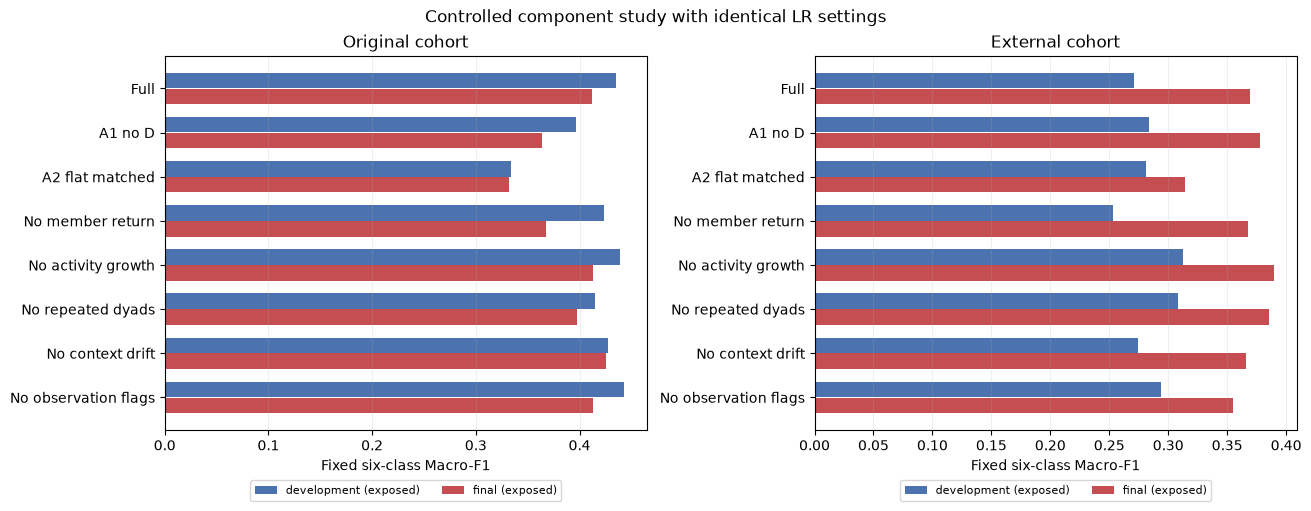

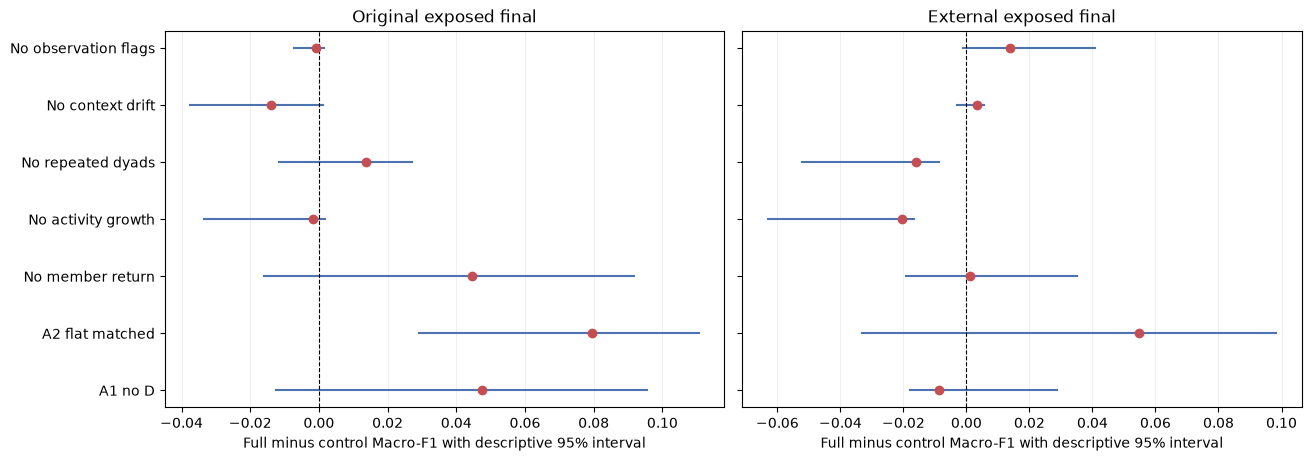

In [7]:
# Verify actual component predictions before displaying their measured scores.
from reddit_sna.reporting.components import read_components, render_components, component_figures
component_root = project / "artifacts/components/controlled-002"
component_data = read_components(component_root)
display(Markdown(render_components(component_data)))
for component_name, component_figure in component_figures(component_data).items():
    display(component_figure)
    plt.close(component_figure)


In [8]:
# Compare per-class performance with the same three seeds and fixed six labels.
# Support is counted once per sample, not multiplied by the number of seeds.
import numpy as np
from reddit_sna.evaluation.temporal_protocol import EVENTS
class_rows = []
for event in EVENTS:
    values = []
    for cohort_name in ("original", "external"):
        measured = component_data[cohort_name]["final"]["per_seed"]
        support = measured["full"]["42"]["per_class"][event]["support"]
        full_f1 = np.mean([measured["full"][str(s)]["per_class"][event]["f1"] for s in (42,43,44)])
        flat_f1 = np.mean([measured["A2_flat_matched"][str(s)]["per_class"][event]["f1"] for s in (42,43,44)])
        values.extend((str(support), f"{full_f1:.4f}", f"{flat_f1:.4f}"))
    class_rows.append("| " + event + " | " + " | ".join(values) + " |")
display(Markdown("| Event | Original support | Full F1 | A2 F1 | External support | Full F1 | A2 F1 |\n"
    "|---|---:|---:|---:|---:|---:|---:|\n" + "\n".join(class_rows)))


| Event | Original support | Full F1 | A2 F1 | External support | Full F1 | A2 F1 |
|---|---:|---:|---:|---:|---:|---:|
| stable | 4 | 0.0000 | 0.0146 | 1 | 0.0000 | 0.0606 |
| grow | 19 | 0.0968 | 0.0613 | 8 | 0.0000 | 0.1071 |
| shrink | 25 | 0.4444 | 0.3182 | 14 | 0.4865 | 0.4615 |
| merge | 15 | 0.2308 | 0.2195 | 9 | 0.2667 | 0.0000 |
| split | 39 | 0.7397 | 0.6567 | 4 | 0.5455 | 0.5455 |
| dissolve | 1167 | 0.9587 | 0.7225 | 250 | 0.9155 | 0.7103 |

## Predeclared new-cohort replication

Anarchism, Libertarian and GreenParty were declared before acquisition. The
35-field candidate removes only activity-growth fields. Every baseline and
control was fixed before this collection's outcomes. The original 37-field
primary and all five headline baseline roles remain visible. The reader below
checks acquisition/freeze chronology, saved predictions and recomputed metrics.


## 10. Predeclared new-cohort replication

### Design and candidate rationale

The supplementary component study motivated a candidate that removes only
record_log_growth and reply_log_growth. It retains 35 of the original 37 fields,
including member-return history, repeated interactions, context drift and
observation indicators. Its two-head LR uses C=1, balanced class weighting and
training-only standard scaling. This candidate and every comparator were fixed
before downloading Anarchism, Libertarian and GreenParty from Cornell.
These corpora had not been used in the recorded project studies. Prior exposure
by other team members is uncertified and users may overlap earlier collections.

Acquisition records observed SHA-256 and ZIP CRC checks. Development metadata,
graphs and labels end before January 2018. Models fit pre-2018 targets and freeze
before January to September 2018 graphs and outcome labels are constructed.
The development prefix is verified unchanged after extension. Graph, Leiden,
GED-adapted label rules and six event order remain consistent with the earlier
study. All methods share one reference, eligible sample set and context schema
inside this cohort. There is no new hyperparameter search or outcome-based
corpus substitution. Raw archives and private assessment cases remain local.

### Measured results

The new collection contributes 1577 resolved pre-2018 training transitions
and 493 resolved final transitions out of
746 observed final source transitions. Its final
resolved fraction is 66.09%. The remaining
253 observed transitions are unresolved and
are not forced into the six classes. There are 90 separately
censored last-snapshot groups. Raw archive size is an acquisition statistic,
not the number of independent training or evaluation samples.

| Configuration | New-cohort Macro-F1 |
|---|---:|
| B1_majority | 0.1576 |
| B1_persistence | 0.1526 |
| flat_lr_dynamic | 0.2789 |
| hier_hgb_static | 0.3214 |
| hier_hgb_dynamic | 0.4044 |
| hier_lr_dynamic | 0.3646 |
| A_no_dynamics_matched | 0.3320 |
| hier_lr_pruned_growth | 0.3631 |
| A_flat_pruned_matched | 0.3190 |

Scores average algorithm seeds 42/43/44. Candidate minus strongest realized
named baseline (hier_hgb_dynamic) is -0.0413, with
descriptive paired 95% interval [-0.0685, +0.0159], and a higher monthly score in
5/9 months. The primary comparator
was predeclared as dynamic HGB. The realized strongest alternative is identified
after evaluation for transparent reporting. Intervals are unadjusted exploratory
time-block comparisons, not a correction for choosing the strongest after evaluation.
Old final scores are not pooled with this new cohort and no model is replaced
because of the new final outcomes.

Candidate minus the original 37-field hierarchical LR is
-0.0014, with descriptive 95% interval [-0.0054, +0.0073].
This direct comparison tests whether removing activity-growth fields transfers
to the new collection, separately from whether either version beats a named
baseline. Both versions and all disagreements remain in the result inventory.

| Event | New-cohort support | Candidate F1 | Original full F1 | Strongest baseline F1 |
|---|---:|---:|---:|---:|
| stable | 0 | 0.0000 | 0.0000 | 0.0000 |
| grow | 7 | 0.1739 | 0.1739 | 0.3636 |
| shrink | 34 | 0.3194 | 0.3158 | 0.3488 |
| merge | 0 | 0.0000 | 0.0000 | 0.0000 |
| split | 10 | 0.8421 | 0.8421 | 0.8000 |
| dissolve | 442 | 0.8434 | 0.8557 | 0.9140 |

Per-class F1 averages the same three seeds. Support counts transitions once.
Unresolved and censored populations remain in the source audit denominators.
Operational labels describe measured structural continuation, not independent
social ground truth. Technical rule checks and case-based structural assessment
are separate from completed independent human validation.


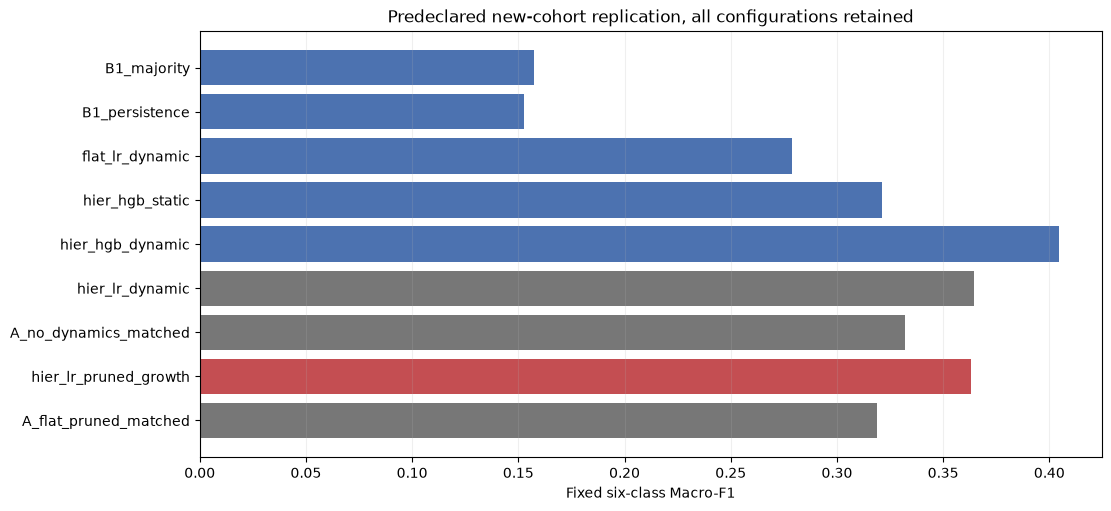

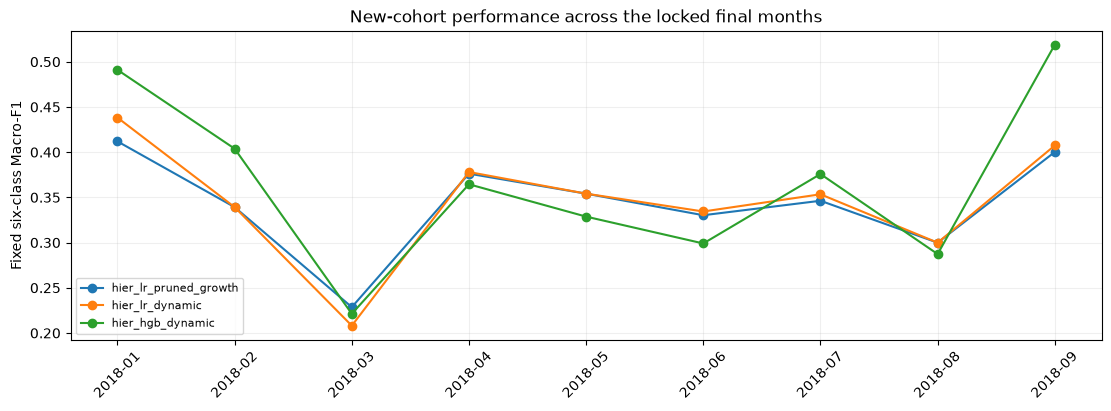

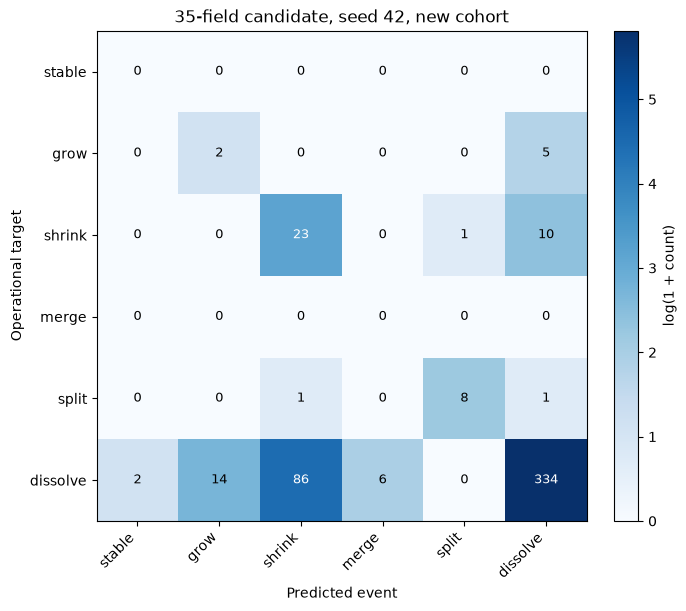

In [9]:
# Read sealed evidence without refitting or changing any stored predictions.
from reddit_sna.reporting.prospective import read_prospective, render_prospective, prospective_figures
prospective_root = project / "artifacts/prospective/ideological-001"
prospective_data = read_prospective(prospective_root)
display(Markdown(render_prospective(prospective_data)))
for prospective_name, prospective_figure in prospective_figures(prospective_data).items():
    # Improve contrast of count labels on the logarithmic confusion colors.
    # This changes presentation only. Matrix counts and metric inputs stay fixed.
    import numpy as np
    for prospective_axis in prospective_figure.axes:
        for prospective_image in prospective_axis.images:
            colors = np.asarray(prospective_image.get_array())
            for count_text in prospective_axis.texts:
                column, row = (int(round(v)) for v in count_text.get_position())
                count_text.set_color("white" if colors[row, column] > colors.max() / 2 else "black")
    display(prospective_figure)
    plt.close(prospective_figure)


In [10]:
# Report only source-bound aggregate technical checks, never private case tokens.
import json
from reddit_sna.pipelines.study_preparation import verified
technical_root = prospective_root.parent / (prospective_root.name + "-technical-assessment")
verified(technical_root)
technical = json.loads((technical_root / "summary.json").read_text(encoding="utf-8"))
assert technical["reviewer_type"] == "automated"
assert technical["independent_human_submissions"] == 0
display(Markdown(f"Technical structural checks: {technical['cases']} cases, "
    f"{technical['discrepancies']} discrepancies. "
    "These are technical assessments, not independent human or social validation."))


Technical structural checks: 21 cases, 6 discrepancies. These are technical assessments, not independent human or social validation.

## Midterm 1 conclusions

The prototype connects raw input, monthly user networks, operational evolution
labels, past-only features, temporal forecasting and evaluation. The report covers
the requested detailed plan, five baseline results, preliminary proposed results,
comparison and prototype demonstration.

On the two earlier collections, the original proposed model scores **0.4117 versus 0.3880** for the strongest named baseline
on the original cohort, and **0.3690 versus 0.3500** on the external cohort.
These positive point differences are preliminary. The paired intervals include
zero, and the external no-dynamics control scores **0.3777**, above the primary.
The general benefit of dynamics is therefore not established.

The development audit finds later match candidates for **20/2,450** fully observed
original-cohort groups labeled dissolve and **12/781** in the external cohort.
Direct matches are candidates, not verified social identities. No accepted match
over three observed months does not prove permanent social disappearance.
Saved seed ARI measures repeatability, not social accuracy. The supplementary
structural assessments are automated; independent human label validation remains
a future research milestone.

The current task remains operational next-month structural forecasting. A new
longer-horizon target needs versioned labels, explicit outcome availability and
whole-month temporal separation before a new evaluation. No model or label is
replaced using the observed final outcomes.

The separately predeclared replication acquires Anarchism, Libertarian and
GreenParty, fits before 2018 and evaluates 493 resolved final transitions.
The 35-field candidate scores 0.3631 versus 0.4044 for dynamic HGB and 0.3646
for the original 37-field model. Its difference from HGB is -0.0413, with
descriptive paired interval [-0.0685, +0.0159]. No method is replaced from
these outcomes. Thus the earlier positive advantage has not replicated here.
Stable and merge have zero final support, so this collection cannot establish
performance on those events. The six-class metric retains their zero scores.

All 21 supplementary development cases have source-bound technical judgments
with confidence and a rationale, supplied before opening the answer key.
Fifteen agree with the operational tracker. Six growth/merge cases remain
uncertain from marginal summaries, which do not establish every accepted
incoming link. This is technical interpretation evidence, not human agreement
or proof that the remaining six labels are wrong. No independent human
validation is claimed. It is supplementary to the five required submission
components, rather than a stated prerequisite of the supplied Midterm 1 brief.
